# Detecção de fraude em transações de cartão de crédito

Este notebook desenvolve um sistema de classificação de transações de cartão de crédito em normais ou fraudulentas, usando o conjunto de dados *Credit Card Fraud Detection* (Machine Learning Group, ULB), com 284.807 transações. São comparados um modelo supervisionado (Regressão Logística) e um modelo de deep learning (MLP), avaliados com métricas adequadas a dados desbalanceados.

## 1. Dados

O conjunto contém transações realizadas por titulares de cartões europeus ao longo de dois dias. A coluna `Time` indica os segundos desde a primeira transação, `Amount` é o valor e `Class` é a resposta (0 = normal, 1 = fraude). As colunas `V1` a `V28` são resultado de uma transformação PCA aplicada pelos autores para proteger a privacidade, por isso seu significado original não é conhecido.

In [1]:
import pandas as pd

df = pd.read_csv('/content/creditcard.csv')
print(df.shape)  # mostra (linhas, colunas)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Análise exploratória

Esta etapa verifica a estrutura e a qualidade dos dados. Não há valores ausentes e todas as colunas são numéricas, dispensando tratamento de nulos e codificação de variáveis categóricas. A principal característica é o forte desbalanceamento: apenas 0,17% das transações são fraudes. Por isso a acurácia isolada não é uma métrica adequada, pois um modelo que classificasse tudo como normal teria acurácia próxima de 99,8% sem detectar nenhuma fraude.

In [2]:
# Mostra o tipo de cada coluna e quantas linhas não estão vazias
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [3]:
# Conta quantos valores vazios existem em cada coluna
print(df.isnull().sum().sum())  # total de valores vazios

0


In [4]:
# Conta quantas transações são normais (0) e quantas são fraude (1)
print(df['Class'].value_counts())

# Mostra em porcentagem
print(df['Class'].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


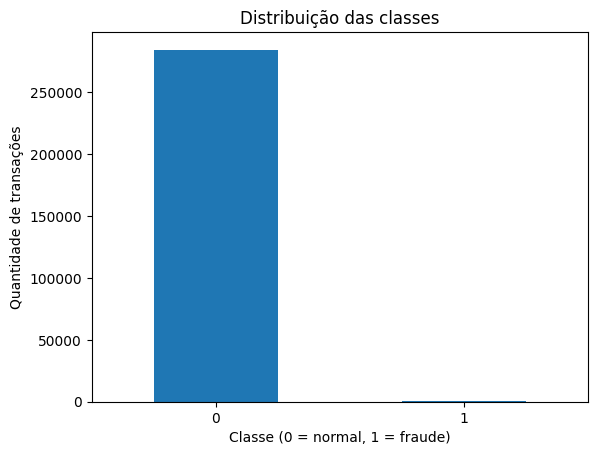

In [5]:
import matplotlib.pyplot as plt  # biblioteca de gráficos

df['Class'].value_counts().plot(kind='bar')
plt.title('Distribuição das classes')
plt.xlabel('Classe (0 = normal, 1 = fraude)')
plt.ylabel('Quantidade de transações')
plt.xticks(rotation=0)
plt.show()

In [6]:
# Resumo estatístico de Amount e Time
print(df[['Time', 'Amount']].describe())

                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


## 3. Pré-processamento

Os dados são divididos em 80% para treino e 20% para teste, de forma estratificada (`stratify`), mantendo a mesma proporção de fraudes nos dois conjuntos. As colunas `Time` e `Amount`, que têm escalas muito diferentes das demais, são padronizadas. O `StandardScaler` é ajustado apenas com o treino e depois aplicado ao teste, para que nenhuma informação do teste influencie o treinamento (evitando vazamento de dados).

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)  # tudo, menos a resposta
y = df['Class']               # só a resposta (0 ou 1)

# Primeiro divide em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% para teste
    random_state=42,     # garante que o resultado seja repetível
    stratify=y           # mantém a proporção de fraudes nos dois grupos
)

# O scaler aprende média e desvio só com o treino; o teste só é transformado
scaler = StandardScaler()
colunas = ['Time', 'Amount']
X_train[colunas] = scaler.fit_transform(X_train[colunas])
X_test[colunas] = scaler.transform(X_test[colunas])

# Renomeia para manter os nomes usados no resto do notebook
X_train = X_train.rename(columns={'Time': 'Time_pad', 'Amount': 'Amount_pad'})
X_test = X_test.rename(columns={'Time': 'Time_pad', 'Amount': 'Amount_pad'})

print('Treino:', X_train.shape, '| Fraudes:', y_train.sum())
print('Teste: ', X_test.shape, '| Fraudes:', y_test.sum())

Treino: (227845, 30) | Fraudes: 394
Teste:  (56962, 30) | Fraudes: 98


### 3.1 PCA e LDA

O PCA é uma técnica não supervisionada que projeta os dados em novas dimensões que preservam a maior variância possível. Aqui é usado com 2 componentes, apenas para visualização, e preserva 58,9% (é a soma de 0,5123 + 0,0764) da variância. O LDA é supervisionado: usa a coluna `Class` para encontrar a direção que melhor separa as duas classes, gerando 1 componente. Ele é ajustado só no treino e depois usado para comparar o desempenho com e sem redução de dimensionalidade.

Variância explicada: [0.51227416 0.07640269]


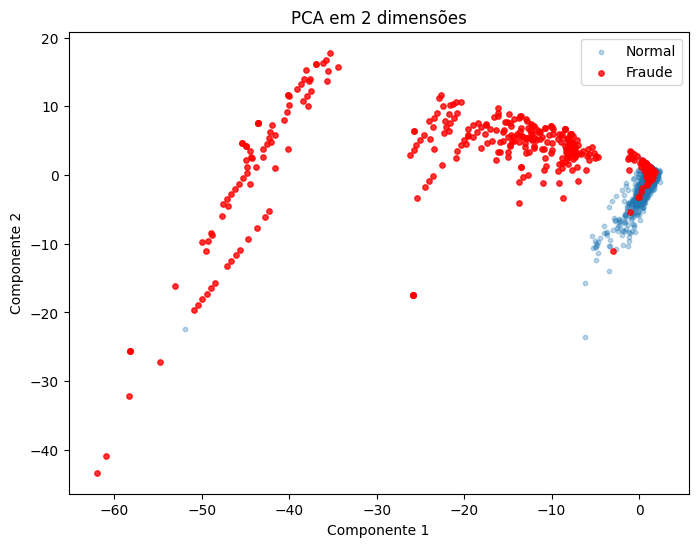

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Junta atributos e resposta do treino
treino = pd.concat([X_train, y_train], axis=1)

# Amostra: todas as fraudes + 5000 normais (para o gráfico não ficar pesado)
fraudes = treino[treino['Class'] == 1]
normais = treino[treino['Class'] == 0].sample(5000, random_state=42)
amostra = pd.concat([fraudes, normais])

X_amostra = amostra.drop('Class', axis=1)
y_amostra = amostra['Class']

# PCA com 2 componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_amostra)

print('Variância explicada:', pca.explained_variance_ratio_)

# Gráfico
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[y_amostra == 0, 0], X_pca[y_amostra == 0, 1],
            alpha=0.3, label='Normal', s=10)
plt.scatter(X_pca[y_amostra == 1, 0], X_pca[y_amostra == 1, 1],
            alpha=0.8, label='Fraude', s=15, color='red')
plt.title('PCA em 2 dimensões')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend()
plt.show()

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)

print(X_train_lda.shape, X_test_lda.shape)

(227845, 1) (56962, 1)


## 4. Modelo supervisionado: Regressão Logística

A Regressão Logística é um modelo linear simples e rápido, adequado como referência inicial. O parâmetro `class_weight='balanced'` aumenta o peso das fraudes durante o treinamento para compensar o desbalanceamento. Com o limiar padrão de 0,5, o modelo detecta muitas fraudes, mas gera muitos falsos positivos, o que resulta em baixa precisão. Em seguida, o limiar de decisão é ajustado para melhorar esse equilíbrio.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

modelo_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
modelo_lr.fit(X_train, y_train)   # aqui o modelo "aprende"

y_pred = modelo_lr.predict(X_test)  # previsões no teste

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=4))

[[55478  1386]
 [    8    90]]
              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962



AUC-ROC: 0.9721687370080279
AUC-PR : 0.7159122424484009


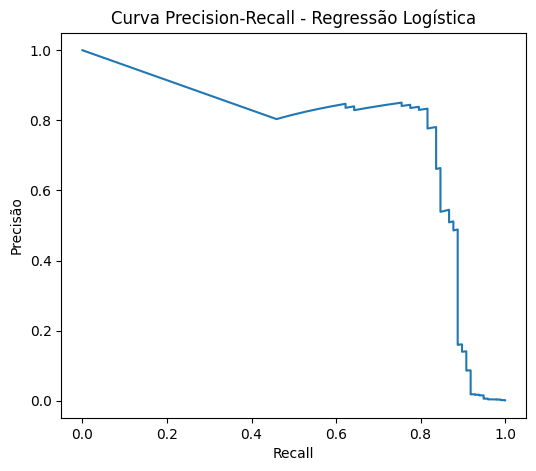

In [11]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

# Probabilidade de ser fraude para cada transação do teste
y_prob = modelo_lr.predict_proba(X_test)[:, 1]

print('AUC-ROC:', roc_auc_score(y_test, y_prob))
print('AUC-PR :', average_precision_score(y_test, y_prob))

# Curva Precision-Recall
prec, rec, _ = precision_recall_curve(y_test, y_prob)
plt.figure(figsize=(6, 5))
plt.plot(rec, prec)
plt.title('Curva Precision-Recall - Regressão Logística')
plt.xlabel('Recall')
plt.ylabel('Precisão')
plt.show()

In [12]:
import numpy as np
from sklearn.metrics import f1_score

# Testa vários limiares de 0.05 a 0.99
limiares = np.arange(0.05, 1.0, 0.01)
f1s = [f1_score(y_test, (y_prob >= t).astype(int)) for t in limiares]

melhor = limiares[np.argmax(f1s)]
print('Melhor limiar:', round(melhor, 2))
print('F1 nesse limiar:', round(max(f1s), 4))

# Resultado com o novo limiar
y_pred_novo = (y_prob >= melhor).astype(int)
print(confusion_matrix(y_test, y_pred_novo))
print(classification_report(y_test, y_pred_novo, digits=4))

Melhor limiar: 0.99
F1 nesse limiar: 0.686
[[56803    61]
 [   15    83]]
              precision    recall  f1-score   support

           0     0.9997    0.9989    0.9993     56864
           1     0.5764    0.8469    0.6860        98

    accuracy                         0.9987     56962
   macro avg     0.7881    0.9229    0.8426     56962
weighted avg     0.9990    0.9987    0.9988     56962



In [13]:
limiares = np.linspace(0.90, 0.9999, 300)
f1s = [f1_score(y_test, (y_prob >= t).astype(int)) for t in limiares]
print('Melhor limiar:', round(limiares[np.argmax(f1s)], 4))
print('F1:', round(max(f1s), 4))

Melhor limiar: 0.9999
F1: 0.7885


## 5. Modelo de deep learning: MLP

A MLP (Multilayer Perceptron) é uma rede neural com camadas de neurônios totalmente conectadas, capaz de aprender relações não lineares. A arquitetura final tem 30 entradas, duas camadas ocultas (64 e 32 neurônios, ativação ReLU) e uma saída com ativação sigmoide, que retorna a probabilidade de fraude. Essa configuração foi escolhida por uma busca em grade na seção 6. Não foi aplicado peso extra à classe fraude (peso 1), pois pesos maiores não melhoraram a separação das classes nessa busca. O limiar de decisão é escolhido em um conjunto de validação separado do treino, sem usar o teste.

In [14]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report, roc_auc_score, average_precision_score

keras.utils.set_random_seed(42)

# Separa 20% do treino para validação
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Define a rede: 30 entradas -> 32 neurônios -> 16 neurônios -> 1 saída (prob. de fraude)
modelo_mlp = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

modelo_mlp.compile(optimizer='adam', loss='binary_crossentropy')

# Dá mais peso às fraudes (peso 10, valor moderado)
pesos = {0: 1.0, 1: 10.0}

historico = modelo_mlp.fit(
    X_tr.values, y_tr.values,
    validation_data=(X_val.values, y_val.values),
    epochs=20, batch_size=2048,
    class_weight=pesos, verbose=2
)

Epoch 1/20
90/90 - 2s - 17ms/step - loss: 0.2412 - val_loss: 0.0466
Epoch 2/20
90/90 - 0s - 4ms/step - loss: 0.0366 - val_loss: 0.0144
Epoch 3/20
90/90 - 0s - 4ms/step - loss: 0.0225 - val_loss: 0.0099
Epoch 4/20
90/90 - 0s - 4ms/step - loss: 0.0188 - val_loss: 0.0083
Epoch 5/20
90/90 - 0s - 4ms/step - loss: 0.0171 - val_loss: 0.0075
Epoch 6/20
90/90 - 1s - 7ms/step - loss: 0.0160 - val_loss: 0.0071
Epoch 7/20
90/90 - 0s - 4ms/step - loss: 0.0152 - val_loss: 0.0067
Epoch 8/20
90/90 - 0s - 4ms/step - loss: 0.0145 - val_loss: 0.0064
Epoch 9/20
90/90 - 0s - 4ms/step - loss: 0.0139 - val_loss: 0.0062
Epoch 10/20
90/90 - 0s - 4ms/step - loss: 0.0134 - val_loss: 0.0061
Epoch 11/20
90/90 - 0s - 4ms/step - loss: 0.0130 - val_loss: 0.0060
Epoch 12/20
90/90 - 0s - 4ms/step - loss: 0.0126 - val_loss: 0.0059
Epoch 13/20
90/90 - 0s - 4ms/step - loss: 0.0122 - val_loss: 0.0058
Epoch 14/20
90/90 - 0s - 4ms/step - loss: 0.0119 - val_loss: 0.0057
Epoch 15/20
90/90 - 0s - 4ms/step - loss: 0.0115 - val_l

In [15]:
# Escolhe o limiar na VALIDAÇÃO (não no teste)
prob_val = modelo_mlp.predict(X_val.values).ravel()
limiares = np.arange(0.05, 1.0, 0.01)
f1s = [f1_score(y_val, (prob_val >= t).astype(int)) for t in limiares]
lim_mlp = limiares[np.argmax(f1s)]
print('Limiar escolhido na validação:', round(lim_mlp, 2))

# Avalia no TESTE
prob_teste = modelo_mlp.predict(X_test.values).ravel()
y_pred_mlp = (prob_teste >= lim_mlp).astype(int)

print('AUC-ROC:', roc_auc_score(y_test, prob_teste))
print('AUC-PR :', average_precision_score(y_test, prob_teste))
print(confusion_matrix(y_test, y_pred_mlp))
print(classification_report(y_test, y_pred_mlp, digits=4))

1425/1425 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step  
Limiar escolhido na validação: 0.61
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
AUC-ROC: 0.9815732919504324
AUC-PR : 0.7997082068921977
[[56838    26]
 [   16    82]]
              precision    recall  f1-score   support

           0     0.9997    0.9995    0.9996     56864
           1     0.7593    0.8367    0.7961        98

    accuracy                         0.9993     56962
   macro avg     0.8795    0.9181    0.8979     56962
weighted avg     0.9993    0.9993    0.9993     56962



In [16]:
# Regressão Logística treinada só no X_tr, limiar escolhido no X_val
lr_justo = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_justo.fit(X_tr, y_tr)

prob_val_lr = lr_justo.predict_proba(X_val)[:, 1]
limiares = np.linspace(0.05, 0.99999, 2000)
f1s = [f1_score(y_val, (prob_val_lr >= t).astype(int)) for t in limiares]
lim_lr = limiares[np.argmax(f1s)]
print('Limiar escolhido na validação:', round(lim_lr, 5))

# Avalia no teste
prob_teste_lr = lr_justo.predict_proba(X_test)[:, 1]
y_pred_lr = (prob_teste_lr >= lim_lr).astype(int)

print('AUC-PR :', average_precision_score(y_test, prob_teste_lr))
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, digits=4))

Limiar escolhido na validação: 0.99999
AUC-PR : 0.7119388461522609
[[56840    24]
 [   16    82]]
              precision    recall  f1-score   support

           0     0.9997    0.9996    0.9996     56864
           1     0.7736    0.8367    0.8039        98

    accuracy                         0.9993     56962
   macro avg     0.8867    0.9182    0.9018     56962
weighted avg     0.9993    0.9993    0.9993     56962



## 6. Validação cruzada e ajuste de hiperparâmetros

A validação cruzada estratificada com 5 dobras avalia o modelo em diferentes divisões dos dados, mostrando se o resultado é estável ou depende de uma única divisão. A métrica usada é o AUC-PR (área sob a curva Precision-Recall), mais informativa que o AUC-ROC em dados desbalanceados.

Para a Regressão Logística, o GridSearchCV testou combinações de `C` e `class_weight`. A melhor foi `C = 0,1` sem ponderação (AUC-PR de 0,764), e a ponderação `balanced` ficou levemente pior em todas as combinações.

Para a MLP, foram testadas 9 combinações de arquitetura ((16, 8), (32, 16) e (64, 32)) e peso da classe fraude (1, 10 e 50), avaliadas em um conjunto de validação. A melhor foi (64, 32) com peso 1 (AUC-PR de 0,810). Redes maiores tiveram desempenho melhor, e o peso 50 foi o pior em todas as arquiteturas. Como a validação tem poucas fraudes (cerca de 79), diferenças pequenas entre combinações podem ser ruído.

Na validação cruzada com a configuração final, a MLP obteve AUC-PR médio de 0,842 (± 0,031) contra 0,757 (± 0,051) da Regressão Logística, com desempenho superior em todas as dobras. Como parte dos dados usados para escolher a configuração da MLP também aparece nas dobras, esse valor pode ser levemente otimista.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    LogisticRegression(class_weight='balanced', max_iter=1000),
    X_train, y_train, cv=cv, scoring='average_precision'
)
print('AUC-PR em cada dobra:', scores.round(3))
print('Média:', scores.mean().round(3), '| Desvio:', scores.std().round(3))

AUC-PR em cada dobra: [0.815 0.758 0.674 0.806 0.731]
Média: 0.757 | Desvio: 0.051


In [18]:
from sklearn.metrics import average_precision_score

def criar_mlp():
    m = keras.Sequential([
        keras.layers.Input(shape=(X_train.shape[1],)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])
    m.compile(optimizer='adam', loss='binary_crossentropy')
    return m

scores_mlp = []
for i, (idx_tr, idx_va) in enumerate(cv.split(X_train, y_train)):
    keras.utils.set_random_seed(42)  # mesma semente em cada dobra, para o resultado se repetir
    m = criar_mlp()
    m.fit(X_train.values[idx_tr], y_train.values[idx_tr],
          epochs=20, batch_size=2048, class_weight={0: 1.0, 1: 1.0}, verbose=0)
    p = m.predict(X_train.values[idx_va], verbose=0).ravel()
    s = average_precision_score(y_train.values[idx_va], p)
    scores_mlp.append(s)
    print(f'Dobra {i+1}: {s:.3f}')

scores_mlp = np.array(scores_mlp)
print('Média:', scores_mlp.mean().round(3), '| Desvio:', scores_mlp.std().round(3))

Dobra 1: 0.882
Dobra 2: 0.815
Dobra 3: 0.805
Dobra 4: 0.875
Dobra 5: 0.833
Média: 0.842 | Desvio: 0.031


In [19]:
from sklearn.model_selection import GridSearchCV

parametros = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': ['balanced', None]
}

grade = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    parametros, cv=cv, scoring='average_precision', n_jobs=-1
)
grade.fit(X_train, y_train)

print('Melhores parâmetros:', grade.best_params_)
print('Melhor AUC-PR (validação cruzada):', round(grade.best_score_, 3))

# Tabela com todas as combinações
resultados = pd.DataFrame(grade.cv_results_)[['param_C', 'param_class_weight', 'mean_test_score', 'std_test_score']]
print(resultados.sort_values('mean_test_score', ascending=False))

Melhores parâmetros: {'C': 0.1, 'class_weight': None}
Melhor AUC-PR (validação cruzada): 0.764
   param_C param_class_weight  mean_test_score  std_test_score
3     0.10               None         0.763584        0.041202
1     0.01               None         0.762751        0.045885
5     1.00               None         0.762607        0.041071
7    10.00               None         0.761063        0.040547
9   100.00               None         0.760678        0.041185
4     1.00           balanced         0.756997        0.051460
8   100.00           balanced         0.756683        0.051815
6    10.00           balanced         0.756599        0.051716
2     0.10           balanced         0.756545        0.051906
0     0.01           balanced         0.754394        0.051696


In [20]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Modelo final (melhores parâmetros) com os 30 atributos
lr_final = LogisticRegression(C=0.1, max_iter=2000, random_state=42)
lr_final.fit(X_train, y_train)
p_orig = lr_final.predict_proba(X_test)[:, 1]

# Mesmo modelo, usando só o componente do LDA
lr_lda = LogisticRegression(C=0.1, max_iter=2000, random_state=42)
lr_lda.fit(X_train_lda, y_train)
p_lda = lr_lda.predict_proba(X_test_lda)[:, 1]

print('30 atributos -> AUC-PR:', round(average_precision_score(y_test, p_orig), 4),
      '| AUC-ROC:', round(roc_auc_score(y_test, p_orig), 4))
print('LDA (1 comp) -> AUC-PR:', round(average_precision_score(y_test, p_lda), 4),
      '| AUC-ROC:', round(roc_auc_score(y_test, p_lda), 4))

30 atributos -> AUC-PR: 0.7413 | AUC-ROC: 0.9595
LDA (1 comp) -> AUC-PR: 0.7196 | AUC-ROC: 0.9811


In [21]:
import itertools
import pandas as pd
from tensorflow import keras
from sklearn.metrics import average_precision_score

def criar_mlp_grade(camadas):
    """Cria uma MLP com as camadas ocultas indicadas."""
    modelo = keras.Sequential([keras.layers.Input(shape=(X_train.shape[1],))])
    for n in camadas:
        modelo.add(keras.layers.Dense(n, activation='relu'))
    modelo.add(keras.layers.Dense(1, activation='sigmoid'))
    modelo.compile(optimizer='adam', loss='binary_crossentropy')
    return modelo

arquiteturas = [(16, 8), (32, 16), (64, 32)]
pesos_fraude = [1, 10, 50]

resultados_mlp = []
for camadas, peso in itertools.product(arquiteturas, pesos_fraude):
    keras.utils.set_random_seed(42)  # mesma semente em cada treino, para comparar de forma justa
    m = criar_mlp_grade(camadas)
    m.fit(X_tr.values, y_tr.values, epochs=20, batch_size=2048,
          class_weight={0: 1.0, 1: float(peso)}, verbose=0)
    p_val = m.predict(X_val.values, verbose=0).ravel()
    ap = average_precision_score(y_val, p_val)
    resultados_mlp.append({'camadas': str(camadas), 'peso_fraude': peso, 'AUC-PR (validação)': ap})
    print(camadas, 'peso', peso, '->', round(ap, 3))

res_mlp = pd.DataFrame(resultados_mlp).sort_values('AUC-PR (validação)', ascending=False)
res_mlp.round(3)

(16, 8) peso 1 -> 0.731
(16, 8) peso 10 -> 0.737
(16, 8) peso 50 -> 0.727
(32, 16) peso 1 -> 0.784
(32, 16) peso 10 -> 0.778
(32, 16) peso 50 -> 0.732
(64, 32) peso 1 -> 0.81
(64, 32) peso 10 -> 0.79
(64, 32) peso 50 -> 0.757


,camadas,peso_fraude,AUC-PR (validação)
6,"(64, 32)",1,0.810
7,"(64, 32)",10,0.790
3,"(32, 16)",1,0.784
4,"(32, 16)",10,0.778
8,"(64, 32)",50,0.757
1,"(16, 8)",10,0.737
5,"(32, 16)",50,0.732
0,"(16, 8)",1,0.731
2,"(16, 8)",50,0.727


## 7. Resultados e comparação

As curvas Precision-Recall e ROC comparam os modelos. A curva ROC separa pouco os modelos neste cenário, porque o grande número de transações normais mantém o AUC-ROC alto para todos. A curva Precision-Recall é mais informativa. No conjunto de teste, a MLP obteve o maior AUC-PR (0,800), contra 0,741 da Regressão Logística com C = 0,1, 0,720 da versão com LDA e 0,712 da versão com ponderação `balanced`.

Com limiar escolhido na validação, os dois modelos principais tiveram desempenho praticamente igual: F1 de 0,796 para a MLP e 0,804 para a Regressão Logística, ambas detectando 82 das 98 fraudes (a MLP com 26 alarmes falsos e a Regressão Logística com 24). A vantagem da MLP aparece, portanto, na qualidade geral da separação entre as classes (AUC-PR), e não em um limiar específico. Essas diferenças devem ser interpretadas com cautela, pois o conjunto de teste tem apenas 98 fraudes.

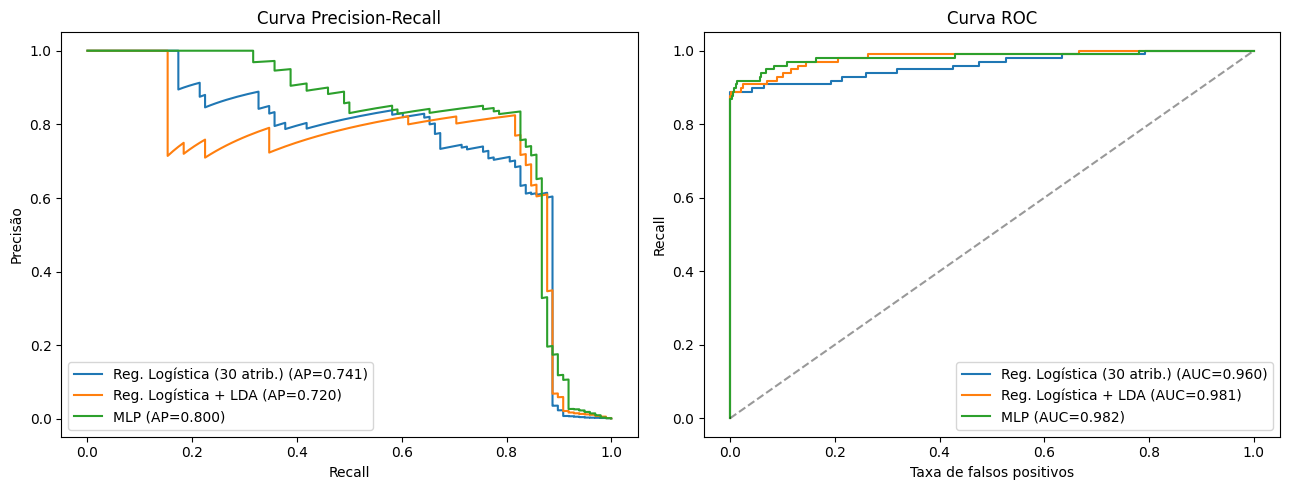

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

modelos = {
    'Reg. Logística (30 atrib.)': p_orig,
    'Reg. Logística + LDA': p_lda,
    'MLP': prob_teste,
}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for nome, p in modelos.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[0].plot(rec, prec, label=f'{nome} (AP={average_precision_score(y_test, p):.3f})')
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[1].plot(fpr, tpr, label=f'{nome} (AUC={roc_auc_score(y_test, p):.3f})')

ax[0].set_title('Curva Precision-Recall')
ax[0].set_xlabel('Recall'); ax[0].set_ylabel('Precisão'); ax[0].legend()
ax[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax[1].set_title('Curva ROC')
ax[1].set_xlabel('Taxa de falsos positivos'); ax[1].set_ylabel('Recall'); ax[1].legend()
plt.tight_layout()
plt.show()

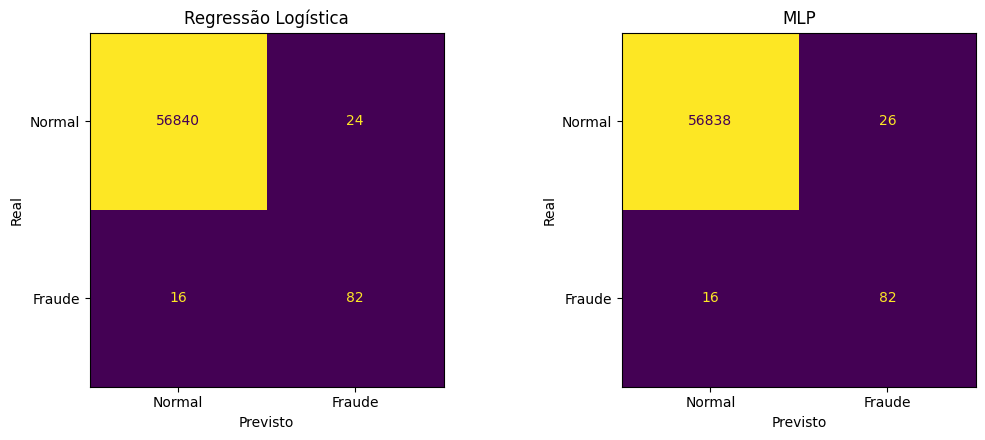

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# Regressão Logística (limiar escolhido na validação)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, ax=ax[0],
    display_labels=['Normal', 'Fraude'], colorbar=False
)
ax[0].set_title('Regressão Logística')

# MLP (limiar escolhido na validação)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_mlp, ax=ax[1],
    display_labels=['Normal', 'Fraude'], colorbar=False
)
ax[1].set_title('MLP')

ax[0].set_xlabel('Previsto'); ax[0].set_ylabel('Real')
ax[1].set_xlabel('Previsto'); ax[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

def resumo(nome, prob, pred=None):
    """Monta uma linha da tabela. Precisão, recall e F1 só entram
    quando o modelo tem limiar escolhido na validação."""
    linha = {'Modelo': nome,
             'AUC-PR': average_precision_score(y_test, prob),
             'AUC-ROC': roc_auc_score(y_test, prob)}
    if pred is not None:
        linha['Precisão'] = precision_score(y_test, pred)
        linha['Recall'] = recall_score(y_test, pred)
        linha['F1'] = f1_score(y_test, pred)
    return linha

tabela = pd.DataFrame([
    resumo('Reg. Logística (balanced, limiar na validação)', prob_teste_lr, y_pred_lr),
    resumo('Reg. Logística (C=0,1, 30 atributos)', p_orig),
    resumo('Reg. Logística + LDA (1 componente)', p_lda),
    resumo('MLP (limiar na validação)', prob_teste, y_pred_mlp),
])

tabela = tabela.set_index('Modelo').round(3).fillna('-')
tabela

,AUC-PR,AUC-ROC,Precisão,Recall,F1
Modelo,,,,,
"Reg. Logística (balanced, limiar na validação)",0.712,0.974,0.774,0.837,0.804
"Reg. Logística (C=0,1, 30 atributos)",0.741,0.960,-,-,-
Reg. Logística + LDA (1 componente),0.720,0.981,-,-,-
MLP (limiar na validação),0.800,0.982,0.759,0.837,0.796


## 8. Análise de erros

Esta etapa examina as fraudes que a MLP não detectou. A comparação das probabilidades atribuídas mostra se o modelo ficou em dúvida ou se considerou esses casos normais com segurança. Comparar também o valor das transações ajuda a verificar se o erro está associado ao montante.

A MLP deixou passar 16 das 98 fraudes do teste. Essas fraudes receberam probabilidade média de 0,115, contra 0,972 nas detectadas, o que indica que o modelo as considerou normais com bastante segurança. Isso é coerente com a sobreposição entre fraudes e transações normais observada no gráfico do PCA. O valor padronizado médio das transações foi de 0,128 nas fraudes que passaram e 0,072 nas detectadas, uma diferença pequena e baseada em poucos casos, que não permite concluir que o montante explique o erro.

In [25]:
teste = X_test.copy()
teste['Class'] = y_test.values
teste['prob_mlp'] = prob_teste
teste['pred_mlp'] = y_pred_mlp

fn = teste[(teste['Class'] == 1) & (teste['pred_mlp'] == 0)]  # fraudes que passaram
tp = teste[(teste['Class'] == 1) & (teste['pred_mlp'] == 1)]  # fraudes detectadas

print('Fraudes que passaram:', len(fn), '| Detectadas:', len(tp))
print('\nValor padronizado (Amount_pad) médio:')
print('  Passaram:  ', round(fn['Amount_pad'].mean(), 3))
print('  Detectadas:', round(tp['Amount_pad'].mean(), 3))
print('\nProbabilidade média atribuída pela MLP:')
print('  Passaram:  ', round(fn['prob_mlp'].mean(), 3))
print('  Detectadas:', round(tp['prob_mlp'].mean(), 3))

Fraudes que passaram: 16 | Detectadas: 82

Valor padronizado (Amount_pad) médio:
  Passaram:   0.128
  Detectadas: 0.072

Probabilidade média atribuída pela MLP:
  Passaram:   0.115
  Detectadas: 0.972


## 9. Limitações

- O conjunto de teste tem poucas fraudes (98), então as métricas variam bastante com poucos casos.
- As colunas `V1` a `V28` são anônimas, o que dificulta interpretar por que o modelo decide.
- O limiar de decisão depende do custo relativo entre falso positivo e falso negativo, que não foi definido aqui.
- Os dados cobrem apenas dois dias, de um contexto europeu, e podem não representar outros períodos ou regiões.